Laboratorio 9, Fisica Computacional

Juan Manuel Patiño

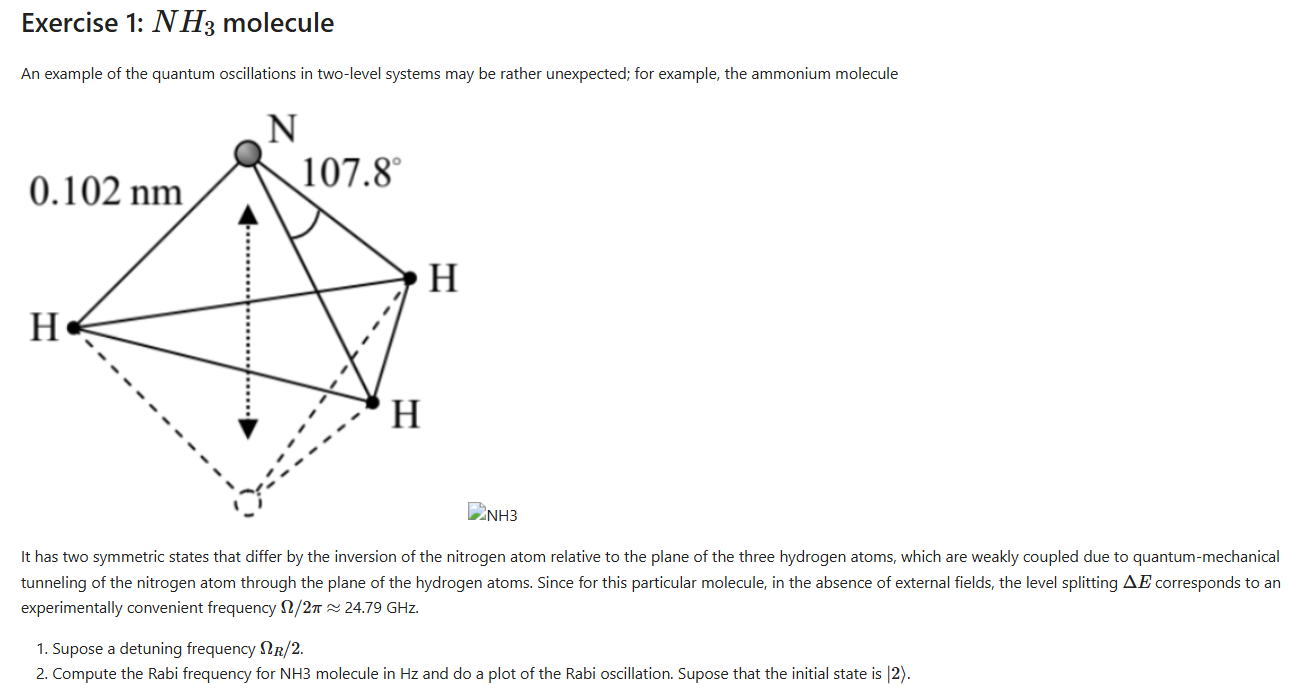

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:

hbar = 1.0545718e-34 # Planck's constant over 2 pi in J*s
#Rabi frequency:
def Omega_Rabi(cx,cy):
    return np.sqrt(cx**2 + cy**2)/hbar
#Detuning:
def Delta(cz):
    return np.abs(cz)/hbar
#Generalized Rabi frequency:
def Omega(cx,cy,cz):
    return np.sqrt(Omega_Rabi(cx,cy)**2 + Delta(cz)**2)
#Probability of staying in the initial state at time t
#(con estado inicial |2> esta es P_2(t)):
def P1(cx,cy,cz,t):
    return np.cos(Omega(cx,cy,cz)*t)**2 + np.sin(Omega(cx,cy,cz)*t)**2*(Delta(cz)/Omega(cx,cy,cz))**2

Rabi frequency: 2.217e+10 Hz
Detuning: 1.109e+10 Hz
Generalized Rabi frequency: 2.479e+10 Hz


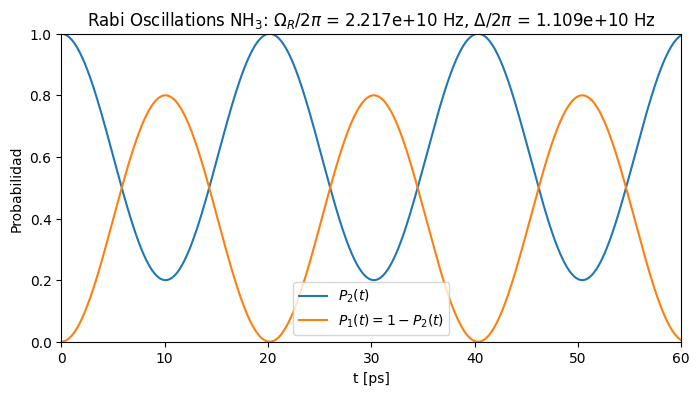

In [6]:
omega0 = 2*np.pi*24.79e9                     # Omega [rad/s]
cx = (2/np.sqrt(5))*omega0*hbar/np.sqrt(2)   # Omega_R = 2*Omega/sqrt(5)
cy = cx
cz = omega0*hbar/np.sqrt(5)                  # hbar*Delta = hbar*Omega_R/2

print(f"Rabi frequency: {Omega_Rabi(cx,cy)/(2*np.pi):.3e} Hz")
print(f"Detuning: {Delta(cz)/(2*np.pi):.3e} Hz")
print(f"Generalized Rabi frequency: {Omega(cx,cy,cz)/(2*np.pi):.3e} Hz")

t = np.linspace(0, 60e-12, 1000)             # 0 - 60 ps
P2 = P1(cx,cy,cz,t)                          # estado inicial |2>

plt.figure(figsize=(8, 4))
plt.plot(t*1e12, P2, label='$P_2(t)$')
plt.plot(t*1e12, 1-P2, label='$P_1(t)=1-P_2(t)$')
plt.xlabel('t [ps]')
plt.ylabel('Probabilidad')
plt.xlim(0, 60)
plt.ylim(0, 1)
plt.legend()
plt.title(f'Rabi Oscillations NH$_3$: $\\Omega_R/2\\pi$ = {Omega_Rabi(cx,cy)/(2*np.pi):.3e} Hz, $\\Delta/2\\pi$ = {Delta(cz)/(2*np.pi):.3e} Hz')
plt.show()

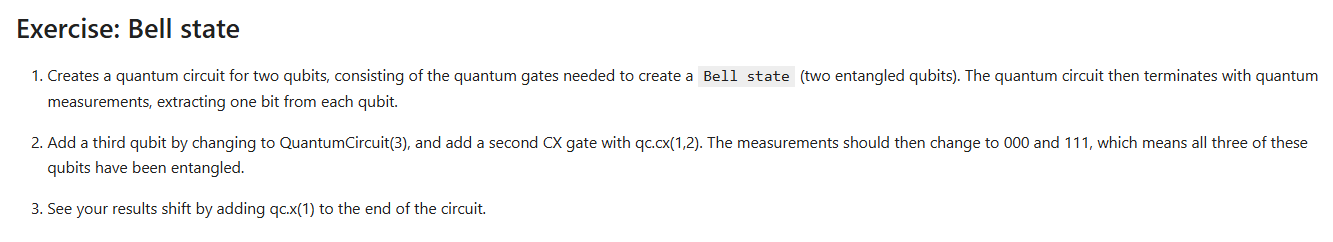

In [7]:
pip install pylatexenc

In [8]:
pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 84.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 92.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]


In [9]:
import qiskit
from qiskit import QuantumCircuit
qiskit.__version__

'2.6.2'

In [11]:
# 1. Crear un circuito cuántico para dos cúbits (Estado de Bell)
# Aplicamos una compuerta Hadamard en el cúbit 0 y una compuerta CNOT (CX) entre 0 y 1.
# Luego medimos ambos cúbits en dos bits clásicos.
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

print(qc.draw('text'))

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


In [14]:
# 2. Agregar un tercer cúbit (QuantumCircuit(3)) y un segundo CX con qc.cx(1,2)
# Esto genera un estado entrelazado de tres cúbits (estado GHZ), resultando en mediciones '000' o '111'.
qc = QuantumCircuit(3, 3)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.measure([0, 1, 2], [0, 1, 2])

print(qc.draw('text'))

     ┌───┐          ┌─┐      
q_0: ┤ H ├──■───────┤M├──────
     └───┘┌─┴─┐     └╥┘┌─┐   
q_1: ─────┤ X ├──■───╫─┤M├───
          └───┘┌─┴─┐ ║ └╥┘┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     0  1  2 


In [16]:
# 3. Ver el cambio en los resultados añadiendo qc.x(1) al final del circuito (antes de medir)
# Esto aplica una compuerta NOT (Pauli-X) al cúbit 1.
qc = QuantumCircuit(3, 3)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.x(1)
qc.measure([0, 1, 2], [0, 1, 2])

print(qc.draw('text'))

     ┌───┐          ┌─┐        
q_0: ┤ H ├──■───────┤M├────────
     └───┘┌─┴─┐     └╥┘┌───┐┌─┐
q_1: ─────┤ X ├──■───╫─┤ X ├┤M├
          └───┘┌─┴─┐ ║ └┬─┬┘└╥┘
q_2: ──────────┤ X ├─╫──┤M├──╫─
               └───┘ ║  └╥┘  ║ 
c: 3/════════════════╩═══╩═══╩═
                     0   2   1 
